# Logistic Regression #

In [6]:
from pathlib import Path
import time
import json
from tqdm.auto import tqdm
import gc

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, matthews_corrcoef, precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import sys

scripts_dir = (Path.cwd() / ".." / "scripts").resolve()
sys.path.append(str(scripts_dir))

from config import final_data_path

final_data_path = Path(final_data_path)
features_dir = final_data_path
results_dir = final_data_path / "modeling_results" / "lr"
results_dir.mkdir(parents=True, exist_ok=True)

target_col = "dep_del15"
non_feature_cols = ["flight_id", "year", target_col]


def get_train_test(key: str):
    """Load one layer, split it by year and drop non-feature columns from X.
    Loaded per layer (not all at once) because the 5-fold CV copies the data."""
    df = pd.read_parquet(features_dir / f"{key}_features.parquet")
    train = df[df["year"] == 2024]
    test = df[df["year"] == 2025]
    del df

    feature_cols = [c for c in train.columns if c not in non_feature_cols]
    X_train, y_train = train[feature_cols], train[target_col].astype(int)
    X_test, y_test = test[feature_cols], test[target_col].astype(int)
    return X_train, y_train, X_test, y_test

In [7]:
lr_params = {
    "C": 1.0,
    "class_weight": "balanced",
    "solver": "lbfgs",
    "max_iter": 2000,
}

beta = 1.2
cv_folds = 5
cv_jobs = 1
random_state = 42

full_layers = [
    "layer_a_bts",
    "layer_b_bts_meteostat",
    "layer_c_bts_gdelt",
    "layer_d_bts_meteostat_gdelt",
]


def make_model():
    """Standardise, then fit the logistic regression."""
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(**lr_params)),
    ])

In [8]:
def tune_threshold(y_true, oof_proba, beta=beta):
    """Pick the threshold that maximizes F-beta on out-of-fold (2024) predictions."""
    precision, recall, thresholds = precision_recall_curve(y_true, oof_proba)
    precision, recall = precision[:-1], recall[:-1]
    fbeta_scores = (
        (1 + beta**2) * precision * recall
        / np.clip(beta**2 * precision + recall, 1e-12, None)
    )
    best_idx = int(np.nanargmax(fbeta_scores))
    return float(thresholds[best_idx])

Run the model on all full-sample layers.

In [9]:
run_results = {}
layer_probas = {}
layer_coefficients = {}
cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)

for key in tqdm(full_layers, desc="LR layers"):
    print(f"\n{'=' * 60}\n{key}\n{'=' * 60}")

    X_train, y_train, X_test, y_test = get_train_test(key)
    print(f"Train: {X_train.shape}, Test: {X_test.shape}")

    n_missing = int(X_train.isna().sum().sum() + X_test.isna().sum().sum())
    assert n_missing == 0, f"{key}: {n_missing} missing values -- imputation would be needed"

    # Out-of-fold probabilities on 2024 -> tune threshold without touching 2025
    start = time.time()
    oof_proba = cross_val_predict(make_model(), X_train, y_train, cv=cv,
                                  method="predict_proba", n_jobs=cv_jobs)[:, 1]
    cv_time = time.time() - start
    threshold = tune_threshold(y_train, oof_proba, beta=beta)
    cv_auc = roc_auc_score(y_train, oof_proba)
    print(f"CV time: {cv_time:.1f}s | OOF AUC-ROC: {cv_auc:.4f}")
    print(f"Tuned threshold (F{beta}, from OOF): {threshold:.4f}")

    # Refit on all of 2024
    model = make_model()
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    if model.named_steps["clf"].n_iter_.max() >= lr_params["max_iter"]:
        print("WARNING: solver hit max_iter -- increase max_iter")
    print(f"Fit time: {elapsed:.1f}s")

    # Real evaluation on 2025 holdout, frozen threshold
    test_proba = model.predict_proba(X_test)[:, 1]
    test_pred = (test_proba >= threshold).astype(int)

    precision = precision_score(y_test, test_pred, zero_division=0)
    recall = recall_score(y_test, test_pred)
    print(f"Precision: {precision:.4f} | Recall: {recall:.4f}")

    metrics = {
        "f1": f1_score(y_test, test_pred),
        "precision": precision,
        "recall": recall,
        "auc_roc": roc_auc_score(y_test, test_proba),
        "auc_pr": average_precision_score(y_test, test_proba),
        "mcc": matthews_corrcoef(y_test, test_pred),
        "threshold": threshold,
        "cv_auc_roc": float(cv_auc),
        "fit_time_s": elapsed,
    }
    print(f"F1: {metrics['f1']:.4f} | AUC-ROC: {metrics['auc_roc']:.4f} | "
          f"AUC-PR: {metrics['auc_pr']:.4f} | MCC: {metrics['mcc']:.4f}")

    # Standardised coefficients: change in log-odds per one SD of the feature
    coefficients = pd.Series(
        model.named_steps["clf"].coef_[0], index=X_train.columns
    ).sort_values(key=np.abs, ascending=False)
    print(f"Top 10 coefficients (by |coef|):\n{coefficients.head(10)}")

    layer_coefficients[key] = coefficients

    # Cache everything needed for threshold experiments without refitting
    layer_probas[key] = {
        "y_train": y_train.to_numpy(),
        "oof_proba": oof_proba,
        "y_test": y_test.to_numpy(),
        "test_proba": test_proba,
    }

    # Save probabilities (needed for DeLong's test and results.ipynb), metrics and coefficients
    np.savez(
        results_dir / f"{key}_probs.npz",
        y_train=y_train.to_numpy(),
        oof_proba=oof_proba,
        y_test=y_test.to_numpy(),
        test_proba=test_proba,
    )
    with open(results_dir / f"{key}_metrics.json", "w") as f:
        json.dump(metrics, f, indent=2)
    coefficients.to_csv(results_dir / f"{key}_coefficients.csv", header=["coef"])

    run_results[key] = metrics

    del model, X_train, X_test
    gc.collect()

# Combined summary table
summary_df = pd.DataFrame(run_results).T
summary_df.index.name = "layer"
summary_df.to_csv(results_dir / "lr_summary.csv")
summary_df

LR layers:   0%|          | 0/4 [00:00<?, ?it/s]


layer_a_bts
Train: (6062137, 25), Test: (5966559, 25)
CV time: 44.5s | OOF AUC-ROC: 0.6768
Tuned threshold (F1.2, from OOF): 0.4669
Fit time: 10.0s
Precision: 0.2987 | Recall: 0.7041
F1: 0.4194 | AUC-ROC: 0.6615 | AUC-PR: 0.3336 | MCC: 0.2000
Top 10 coefficients (by |coef|):
hour_sin           -0.526756
crs_elapsed_time    0.232002
distance           -0.196653
month_cos          -0.194787
origin_te           0.145956
carrier_YX         -0.123090
dest_te             0.091616
dow_sin            -0.089817
carrier_AA          0.063997
carrier_WN          0.057607
dtype: float64


LR layers:  25%|██▌       | 1/4 [01:07<03:21, 67.31s/it]


layer_b_bts_meteostat
Train: (6062137, 29), Test: (5966559, 29)
CV time: 55.3s | OOF AUC-ROC: 0.6821
Tuned threshold (F1.2, from OOF): 0.4718
Fit time: 14.3s
Precision: 0.3047 | Recall: 0.6899
F1: 0.4227 | AUC-ROC: 0.6669 | AUC-PR: 0.3413 | MCC: 0.2064
Top 10 coefficients (by |coef|):
hour_sin           -0.531365
month_cos          -0.227990
origin_te           0.142252
carrier_YX         -0.132493
cldc_mean_12h       0.126613
crs_elapsed_time    0.122515
distance           -0.091232
dest_te             0.089048
dow_sin            -0.088596
carrier_AA          0.066693
dtype: float64


LR layers:  50%|█████     | 2/4 [02:31<02:34, 77.01s/it]


layer_c_bts_gdelt
Train: (6062137, 40), Test: (5966559, 40)
CV time: 77.5s | OOF AUC-ROC: 0.6773
Tuned threshold (F1.2, from OOF): 0.4694
Fit time: 20.5s
Precision: 0.2996 | Recall: 0.6968
F1: 0.4190 | AUC-ROC: 0.6608 | AUC-PR: 0.3328 | MCC: 0.1995
Top 10 coefficients (by |coef|):
hour_sin                    -0.527470
crs_elapsed_time             0.260124
distance                    -0.223664
month_cos                   -0.199850
origin_te                    0.146667
carrier_YX                  -0.121448
gdelt_assault_count_lag7d    0.096438
dow_sin                     -0.094067
dest_te                      0.093558
gdelt_coerce_count_lag7d    -0.066308
dtype: float64


LR layers:  75%|███████▌  | 3/4 [04:23<01:33, 93.29s/it]


layer_d_bts_meteostat_gdelt
Train: (6062137, 44), Test: (5966559, 44)
CV time: 93.7s | OOF AUC-ROC: 0.6827
Tuned threshold (F1.2, from OOF): 0.4753
Fit time: 21.2s
Precision: 0.3060 | Recall: 0.6808
F1: 0.4222 | AUC-ROC: 0.6663 | AUC-PR: 0.3407 | MCC: 0.2060
Top 10 coefficients (by |coef|):
hour_sin                    -0.531141
month_cos                   -0.239192
crs_elapsed_time             0.167792
origin_te                    0.145875
distance                    -0.134096
cldc_mean_12h                0.129542
carrier_YX                  -0.129149
gdelt_assault_count_lag7d    0.094061
dow_sin                     -0.092886
dest_te                      0.092365
dtype: float64


LR layers: 100%|██████████| 4/4 [06:33<00:00, 98.42s/it] 


,f1,precision,recall,auc_roc,auc_pr,mcc,threshold,cv_auc_roc,fit_time_s
layer,,,,,,,,,
layer_a_bts,0.419415,0.298657,0.704113,0.661536,0.333610,0.199952,0.466934,0.676757,9.964367
layer_b_bts_meteostat,0.422675,0.304670,0.689879,0.666947,0.341268,0.206366,0.471772,0.682064,14.305052
layer_c_bts_gdelt,0.419047,0.299619,0.696787,0.660783,0.332806,0.199538,0.469361,0.677255,20.471169
layer_d_bts_meteostat_gdelt,0.422245,0.306025,0.680794,0.666346,0.340674,0.206002,0.475282,0.682655,21.189906


Largest standardised coefficients. Features are standardised, so coefficients are
comparable within a layer: change in log-odds of delay per one standard deviation of the feature.

Top 15 coefficients, layer_a_bts


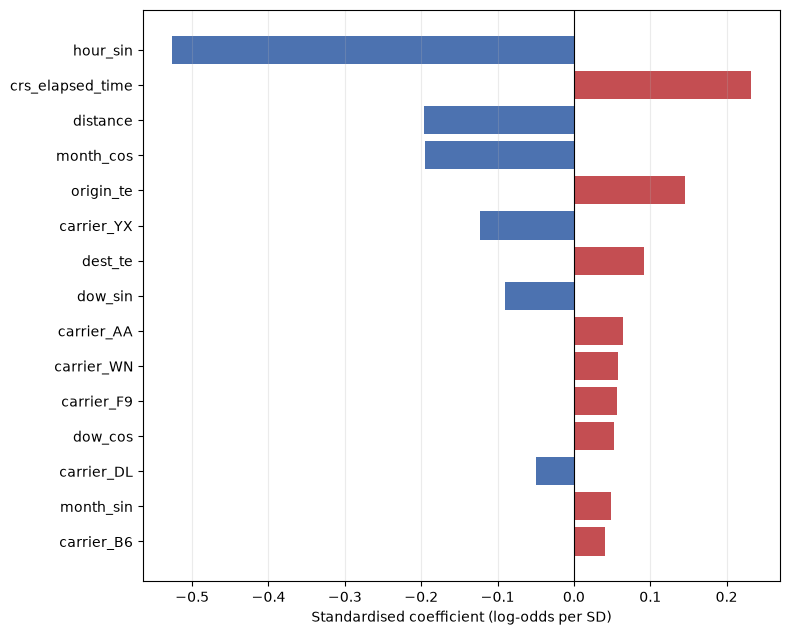

Top 15 coefficients, layer_d_bts_meteostat_gdelt


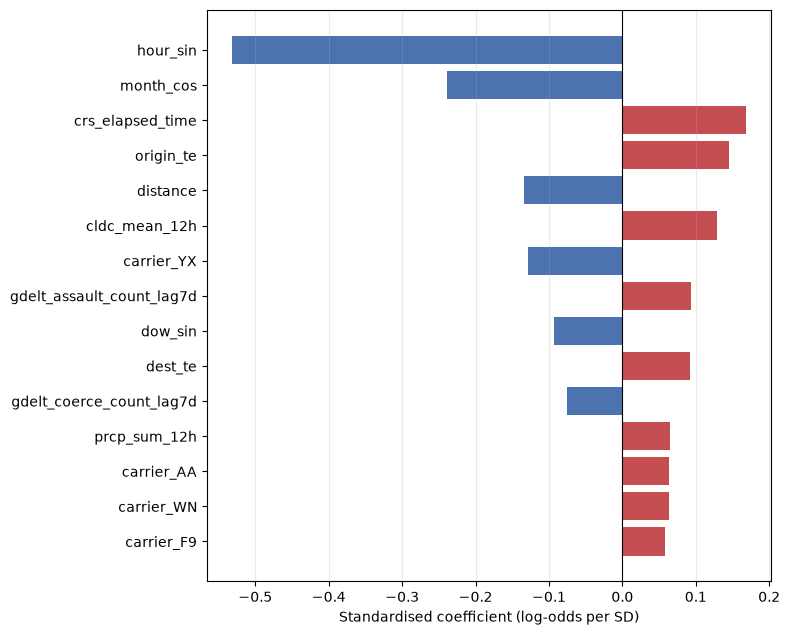

In [10]:
import matplotlib.pyplot as plt

top_n = 15
for key in [full_layers[0], full_layers[-1]]:
    top = layer_coefficients[key].head(top_n)[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.35 * top_n + 1.2))
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "#C44E52", "#4C72B0"))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Standardised coefficient (log-odds per SD)")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    fig.savefig(results_dir / f"lr_coefficients_{key}.png", dpi=200, bbox_inches="tight")
    print(f"Top {top_n} coefficients, {key}")
    plt.show()